# Implementation and Time Analysis of Heap Sort (Max-Heap)

This notebook implements **Heap Sort** using a **Max-Heap** and analyzes its performance.

Heap Sort works in two phases:
1. **Build a Max-Heap** from the input array (largest element ends up at the root)
2. **Repeatedly extract the maximum** (the root) and place it at the end of the array, then re-heapify the reduced heap

For this algorithm you will find:
- Step-by-step Max-Heap construction and heapify logic
- Full Heap Sort implementation
- User input (enter your own list)
- Runtime measurement (using `time` module)
- Time Complexity (Best, Average, Worst case)
- Space Complexity
- A visualization of the max-heap as a binary tree
- A comparison against Python's built-in `sorted()` on larger random data


In [1]:
# Common imports used throughout the notebook
import time
import random
import matplotlib.pyplot as plt

def get_user_list(demo_string=None):
    """Takes a comma-separated list of numbers.

    - Interactive use: call get_user_list() with NO arguments. It will prompt
      you with input() to type your own numbers, e.g.  5,3,8,1,9
    - This notebook (pre-run with saved outputs): the demo cell below calls
      get_user_list(\"5,3,8,...\") with a sample string instead, purely so
      the notebook can be executed top-to-bottom non-interactively and still
      show real output. Remove the argument any time you want to type your
      own list instead.
    """
    raw = demo_string if demo_string is not None else input(
        "Enter numbers separated by commas (e.g., 5,3,8,1,9): "
    )
    try:
        arr = [int(x.strip()) for x in raw.split(',') if x.strip() != '']
    except ValueError:
        print("Invalid input detected, using a default sample list instead.")
        arr = [5, 3, 8, 1, 9, 2]
    return arr


## 1. Max-Heapify

`heapify(arr, n, i)` assumes the binary subtrees rooted at the left and right
children of index `i` are already valid max-heaps, and fixes the subtree rooted
at `i` so the whole thing becomes a valid max-heap (parent >= both children).

For a node at index `i` (0-indexed array representation of a binary tree):
- Left child index  = `2*i + 1`
- Right child index = `2*i + 2`
- Parent index       = `(i - 1) // 2`


In [2]:
def heapify(arr, n, i):
    """Sift down the element at index i so the subtree rooted at i satisfies
    the max-heap property, considering only the first n elements of arr."""
    largest = i
    left = 2 * i + 1
    right = 2 * i + 2

    if left < n and arr[left] > arr[largest]:
        largest = left

    if right < n and arr[right] > arr[largest]:
        largest = right

    if largest != i:
        arr[i], arr[largest] = arr[largest], arr[i]
        heapify(arr, n, largest)   # recursively fix the affected subtree


## 2. Build Max-Heap

To convert an arbitrary array into a max-heap, call `heapify` on every non-leaf
node, starting from the last non-leaf node up to the root (bottom-up). The last
non-leaf node is at index `n // 2 - 1`.


In [3]:
def build_max_heap(arr):
    n = len(arr)
    for i in range(n // 2 - 1, -1, -1):
        heapify(arr, n, i)
    return arr


In [4]:
# --- Demo: building a max-heap from a sample list ---
sample = [4, 10, 3, 5, 1, 8, 9]
print("Original array :", sample)

heap = build_max_heap(sample.copy())
print("Max-Heap array :", heap)
print("(Root =", heap[0], "is the maximum element, as expected in a max-heap)")


Original array : [4, 10, 3, 5, 1, 8, 9]
Max-Heap array : [10, 5, 9, 4, 1, 8, 3]
(Root = 10 is the maximum element, as expected in a max-heap)


## 3. Heap Sort

Once the array is a max-heap, Heap Sort repeatedly:
1. Swaps the root (maximum) with the last element of the current heap
2. Shrinks the heap size by 1 (excluding the now-sorted last element)
3. Calls `heapify` on the root to restore the max-heap property

This is repeated until the heap size is 1, at which point the array is fully sorted in ascending order.


In [5]:
def heap_sort(arr):
    a = arr.copy()
    n = len(a)

    # Step 1: Build a max-heap
    build_max_heap(a)

    # Step 2: Repeatedly extract the max and rebuild the heap
    for end in range(n - 1, 0, -1):
        a[0], a[end] = a[end], a[0]   # move current max to the end
        heapify(a, end, 0)            # re-heapify the reduced heap (size = end)

    return a


In [6]:
# --- Heap Sort: User Input + Runtime ---
# Replace the argument below with nothing, i.e. get_user_list(), to type your own numbers.
user_arr = get_user_list("12,11,13,5,6,7")
print("Original list:", user_arr)

start = time.time()
sorted_arr = heap_sort(user_arr)
end = time.time()

print("Sorted list  :", sorted_arr)
print(f"Runtime      : {(end - start) * 1000:.6f} ms")


Original list: [12, 11, 13, 5, 6, 7]
Sorted list  : [5, 6, 7, 11, 12, 13]
Runtime      : 0.039101 ms


**Time Complexity**
- Building the max-heap: `O(n)`
- Extracting all `n` elements, each costing `O(log n)` for re-heapify: `O(n log n)`
- **Best Case:** `O(n log n)`
- **Average Case:** `O(n log n)`
- **Worst Case:** `O(n log n)`

(Unlike Quick Sort, Heap Sort's performance does **not** degrade on already-sorted or reverse-sorted input — it is consistently `O(n log n)` in every case.)

**Space Complexity:** `O(1)` — Heap Sort sorts in place using the array itself as the heap; only a constant amount of extra space is used for swaps. (The recursive `heapify` uses `O(log n)` call-stack space, which can be turned into `O(1)` iterative form if needed.)

**Not Stable:** Equal elements may not retain their original relative order due to the swapping involved in heap operations.


## 4. Visualizing the Max-Heap as a Binary Tree

The array representation of a heap can be drawn as a binary tree, which makes
the "parent >= children" property easy to see visually.


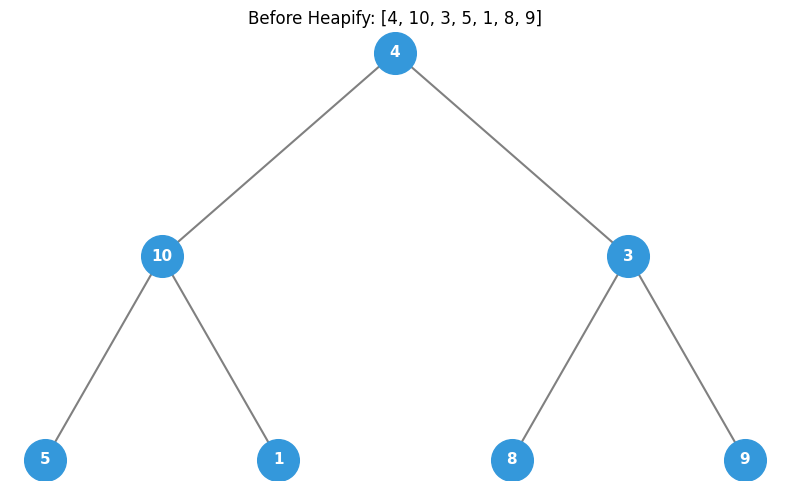

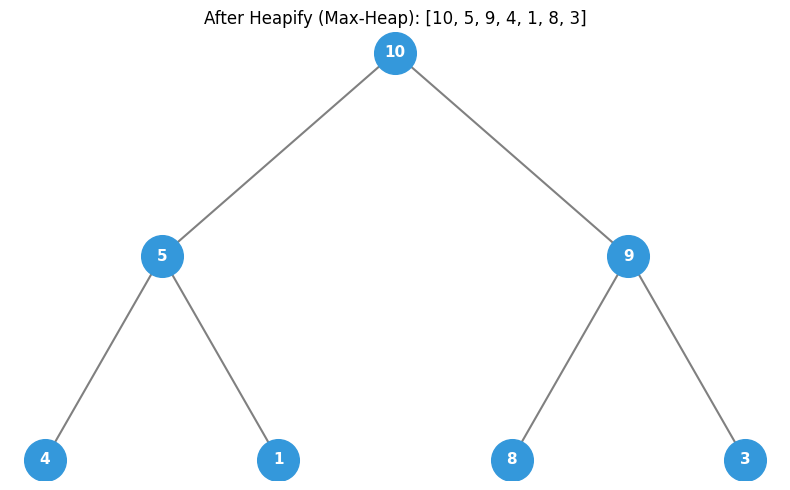

In [7]:
def plot_heap_tree(arr, title="Max-Heap Tree"):
    n = len(arr)
    if n == 0:
        print("Empty heap, nothing to plot.")
        return

    # Assign (x, y) coordinates to each node index using in-order-ish spacing
    positions = {}

    def assign_positions(i, depth, x_min, x_max):
        if i >= n:
            return
        x = (x_min + x_max) / 2
        positions[i] = (x, -depth)
        assign_positions(2 * i + 1, depth + 1, x_min, x)
        assign_positions(2 * i + 2, depth + 1, x, x_max)

    assign_positions(0, 0, 0, 1)

    fig, ax = plt.subplots(figsize=(8, 5))

    # Draw edges first
    for i in range(n):
        for child in (2 * i + 1, 2 * i + 2):
            if child < n:
                x1, y1 = positions[i]
                x2, y2 = positions[child]
                ax.plot([x1, x2], [y1, y2], color='gray', zorder=1)

    # Draw nodes
    for i in range(n):
        x, y = positions[i]
        ax.scatter(x, y, s=900, color='#3498db', zorder=2)
        ax.text(x, y, str(arr[i]), ha='center', va='center', color='white',
                fontsize=11, fontweight='bold', zorder=3)

    ax.set_title(title)
    ax.axis('off')
    plt.tight_layout()
    plt.show()


demo_arr = [4, 10, 3, 5, 1, 8, 9]
heap_version = build_max_heap(demo_arr.copy())
plot_heap_tree(demo_arr, title=f"Before Heapify: {demo_arr}")
plot_heap_tree(heap_version, title=f"After Heapify (Max-Heap): {heap_version}")


## 5. Runtime Comparison: Heap Sort vs Python's Built-in `sorted()`

Python's built-in `sorted()` uses **Timsort** (a highly optimized hybrid of
Merge Sort and Insertion Sort implemented in C), so it will be much faster than
our pure-Python Heap Sort. This comparison shows the overhead of a pure-Python
implementation versus a compiled, production-grade sort.


In [8]:
# --- Compare Heap Sort vs built-in sorted() on random data ---
size = 5000
data = [random.randint(0, 100000) for _ in range(size)]

start = time.time()
heap_result = heap_sort(data)
heap_time = (time.time() - start) * 1000

start = time.time()
builtin_result = sorted(data)
builtin_time = (time.time() - start) * 1000

assert heap_result == builtin_result, "Heap Sort output does not match expected sorted order!"

print(f"Comparison on a random list of {size} elements:\n")
print(f"Heap Sort (pure Python) : {heap_time:.4f} ms")
print(f"Built-in sorted()       : {builtin_time:.4f} ms")


Comparison on a random list of 5000 elements:

Heap Sort (pure Python) : 9.6643 ms
Built-in sorted()       : 0.7389 ms


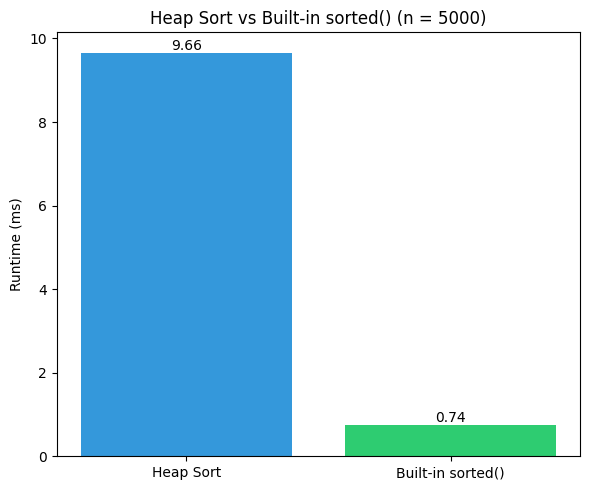

In [9]:
# --- Bar chart of the comparison ---
plt.figure(figsize=(6, 5))
names = ["Heap Sort", "Built-in sorted()"]
times = [heap_time, builtin_time]
bars = plt.bar(names, times, color=['#3498db', '#2ecc71'])
plt.ylabel("Runtime (ms)")
plt.title(f"Heap Sort vs Built-in sorted() (n = {size})")
for bar, t in zip(bars, times):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"{t:.2f}", ha='center', va='bottom')
plt.tight_layout()
plt.show()


## Summary

| Aspect              | Heap Sort                        |
|---------------------|-----------------------------------|
| Best Case           | O(n log n)                        |
| Average Case        | O(n log n)                        |
| Worst Case          | O(n log n)                        |
| Space Complexity    | O(1) (in-place)                   |
| Stable              | No                                 |
| In-Place            | Yes                                |
| Build-Heap Cost     | O(n)                               |

**Notes:**
- Heap Sort guarantees `O(n log n)` in the worst case, unlike Quick Sort — making it a safer choice when worst-case performance matters.
- It sorts in place with `O(1)` extra space, unlike Merge Sort which needs `O(n)`.
- In practice, Quick Sort is often faster than Heap Sort due to better cache locality, and Merge Sort is preferred when stability is required — Heap Sort is chosen when a guaranteed `O(n log n)` with `O(1)` space is the priority (e.g., embedded/memory-constrained systems), or as the basis for priority queues.
